# Explainable ML for Alzheimer's Disease Risk Prediction — OASIS-1
**Healthcare Analytics Mini Project** · Sharwil Bhende (PRN 23070521137) · Symbiosis Institute of Technology, Nagpur

This notebook walks through the full pipeline step by step. The same logic lives in `src/` and can be run headlessly with `python -m src.main`.

**Task:** binary classification of *current* cognitive status — CDR = 0 (normal) vs CDR ≥ 0.5 (impaired) — from demographic, cognitive (MMSE) and MRI-derived (eTIV, nWBV, ASF) features. CDR is used only to build the label.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src import data, eda, models, evaluate, explain, risk
from src.config import FEATURES, DEMOGRAPHIC, COGNITIVE, MRI, SEED, FIG_DIR
pd.set_option('display.precision', 3)

## 1. Data inspection

In [2]:
raw = data.load_raw()
print(raw.shape)
raw.head()

(436, 12)


,ID,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,M,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,M,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 436 entries, 0 to 435
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      436 non-null    str    
 1   M/F     436 non-null    str    
 2   Hand    436 non-null    str    
 3   Age     436 non-null    int64  
 4   Educ    235 non-null    float64
 5   SES     216 non-null    float64
 6   MMSE    235 non-null    float64
 7   CDR     235 non-null    float64
 8   eTIV    436 non-null    int64  
 9   nWBV    436 non-null    float64
 10  ASF     436 non-null    float64
 11  Delay   20 non-null     float64
dtypes: float64(7), int64(2), str(3)
memory usage: 41.0 KB


In [4]:
raw.isna().sum()

ID         0
M/F        0
Hand       0
Age        0
Educ     201
SES      220
MMSE     201
CDR      201
eTIV       0
nWBV       0
ASF        0
Delay    416
dtype: int64

## 2. Cohort selection and target
Keep the first scan per subject (`_MR1`) and subjects with a CDR rating. Target = 1 if CDR ≥ 0.5.

In [5]:
df = data.build_cohort(raw)
data.describe(raw, df)

{'rows_in_file': 436,
 'subjects': 416,
 'reliability_rescans': 20,
 'without_cdr': 181,
 'labelled': 235,
 'normal': 135,
 'impaired': 100,
 'cdr_counts': {'0.0': 135, '0.5': 70, '1.0': 28, '2.0': 2},
 'age_range_all': [18, 96],
 'age_range_labelled': [33, 96],
 'female_labelled': 156,
 'missing_in_features': {'SES': 19},
 'duplicates': 0}

In [6]:
eda.summary_table(df)

,Normal (CDR 0),Impaired (CDR ≥ 0.5)
Age,69.07 ± 13.88,76.76 ± 7.12
Gender,0.28 ± 0.45,0.41 ± 0.49
Educ,3.44 ± 1.26,2.82 ± 1.30
SES,2.33 ± 1.06,2.75 ± 1.17
MMSE,29.10 ± 1.13,24.32 ± 4.17
eTIV,1441.53 ± 152.36,1483.75 ± 168.32
nWBV,0.77 ± 0.05,0.72 ± 0.04
ASF,1.23 ± 0.13,1.20 ± 0.13


## 3. Exploratory analysis

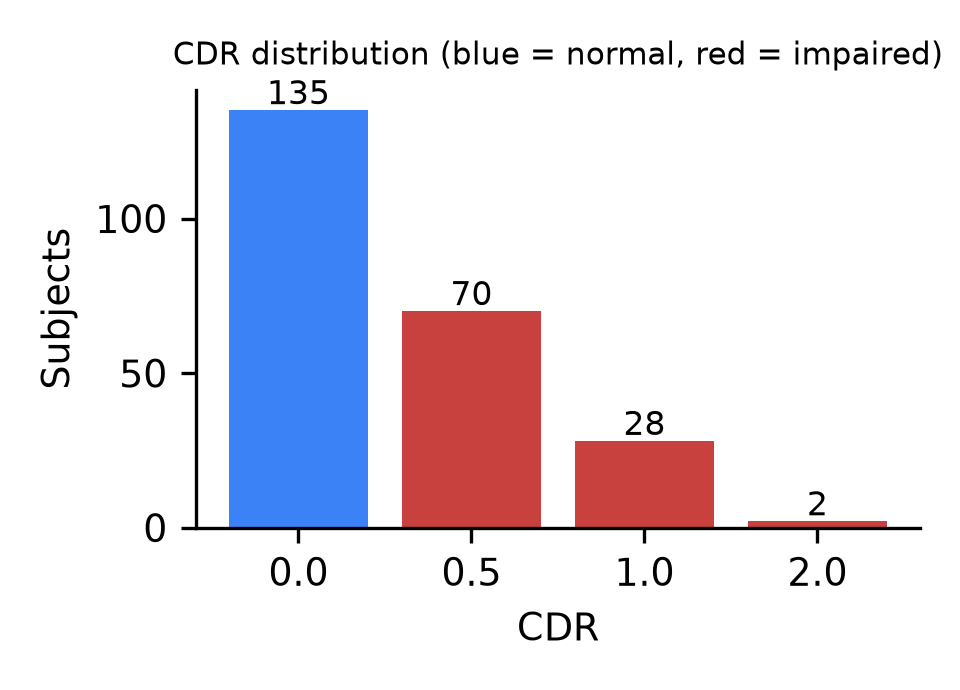

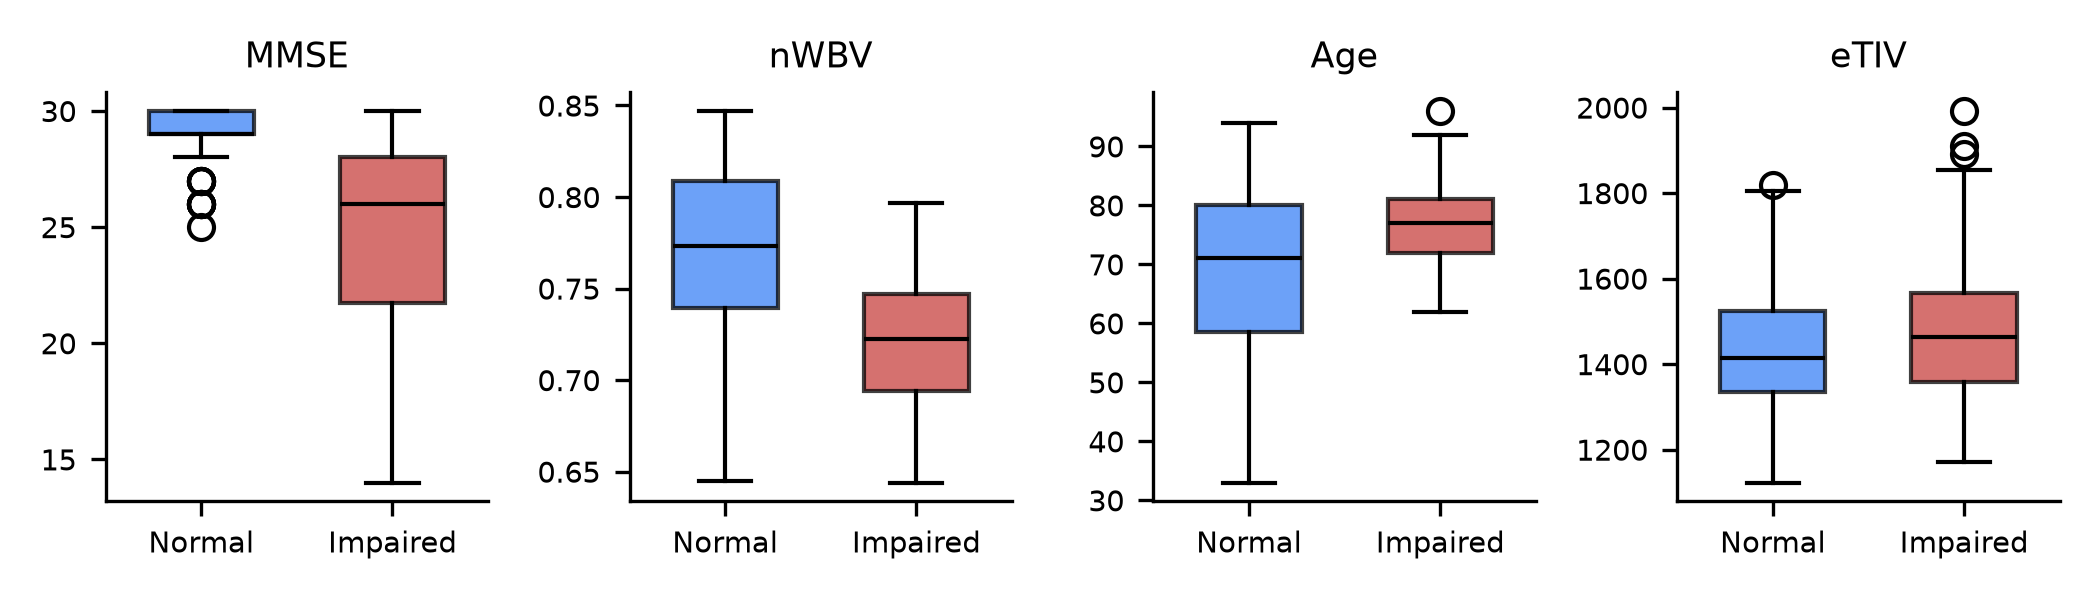

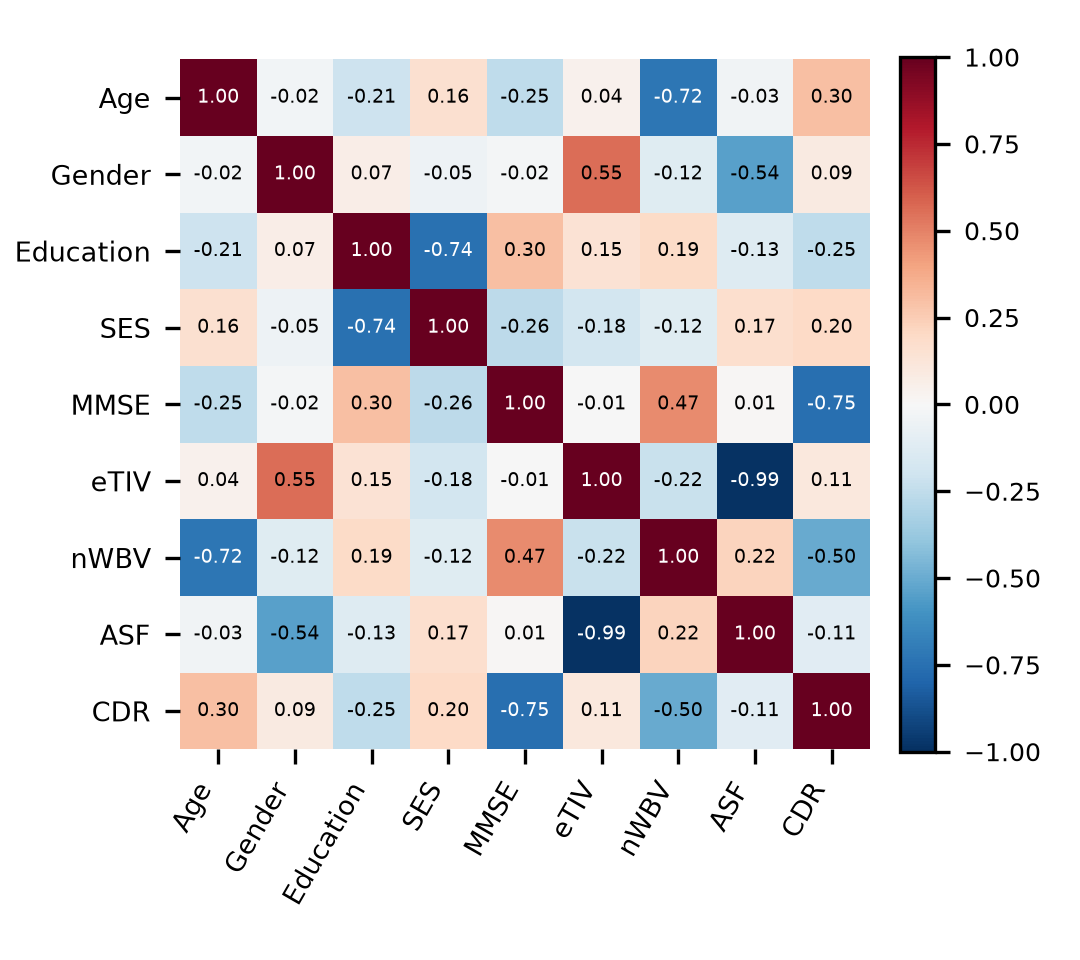

In [7]:
eda.plot_class_balance(df, FIG_DIR/'cdr_distribution.png'); display(Image(FIG_DIR/'cdr_distribution.png', width=380))
eda.plot_distributions(df, FIG_DIR/'feature_boxplots.png'); display(Image(FIG_DIR/'feature_boxplots.png', width=800))
eda.plot_correlation(df, FIG_DIR/'correlation_heatmap.png'); display(Image(FIG_DIR/'correlation_heatmap.png', width=430))

Observations: impaired subjects have lower MMSE and lower nWBV (brain atrophy) and are older. eTIV and ASF are almost perfectly negatively correlated (r ≈ −0.99) because ASF is derived from eTIV.

## 4. Stratified train / test split

In [8]:
X_tr, X_te, y_tr, y_te = data.split(df)
print('train', X_tr.shape, 'impaired', y_tr.sum(), '| test', X_te.shape, 'impaired', y_te.sum())

train (176, 8) impaired 75 | test (59, 8) impaired 25


## 5. Train models
All models are scikit-learn pipelines (median imputation → [scaling] → classifier), so preprocessing is fitted on training data only. SVM and k-NN are extra benchmarks.

In [9]:
zoo = models.build_models(y_tr, include_benchmarks=True)
pd.DataFrame({k: [str(v)] for k, v in models.HYPERPARAMS.items()}, index=['hyperparameters']).T

,hyperparameters
Logistic Regression,"{'penalty': 'l2', 'C': 1.0, 'solver': 'lbfgs',..."
Decision Tree,"{'criterion': 'gini', 'max_depth': 4, 'min_sam..."
Random Forest,"{'n_estimators': 300, 'max_features': 'sqrt', ..."
XGBoost,"{'n_estimators': 200, 'max_depth': 3, 'learnin..."
SVM (RBF),"{'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale', ..."
k-NN,"{'n_neighbors': 7, 'weights': 'distance'}"


In [10]:
rows, probs = {}, {}
for name, m in zoo.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]; probs[name] = p
    met = evaluate.test_metrics(y_te, p)
    met['cv_auc_mean'], met['cv_auc_std'] = evaluate.cv_auc(m, df[FEATURES], df['target'])
    lo, hi = evaluate.bootstrap_auc_ci(y_te, p)
    met['auc_95ci'] = f'{lo:.2f}-{hi:.2f}'
    met.pop('confusion_matrix'); rows[name] = met
res = pd.DataFrame(rows).T
res

,accuracy,precision,recall,specificity,f1,roc_auc,brier,cv_auc_mean,cv_auc_std,auc_95ci
Logistic Regression,0.763,0.72,0.72,0.794,0.72,0.881,0.154,0.901,0.036,0.78-0.95
Decision Tree,0.814,0.792,0.76,0.853,0.776,0.867,0.146,0.854,0.038,0.76-0.95
Random Forest,0.763,0.72,0.72,0.794,0.72,0.898,0.135,0.908,0.023,0.81-0.96
XGBoost,0.78,0.731,0.76,0.794,0.745,0.908,0.132,0.914,0.027,0.82-0.97
SVM (RBF),0.78,0.731,0.76,0.794,0.745,0.876,0.146,0.884,0.035,0.78-0.95
k-NN,0.763,0.739,0.68,0.824,0.708,0.838,0.156,0.849,0.031,0.72-0.93


## 6. Evaluation plots

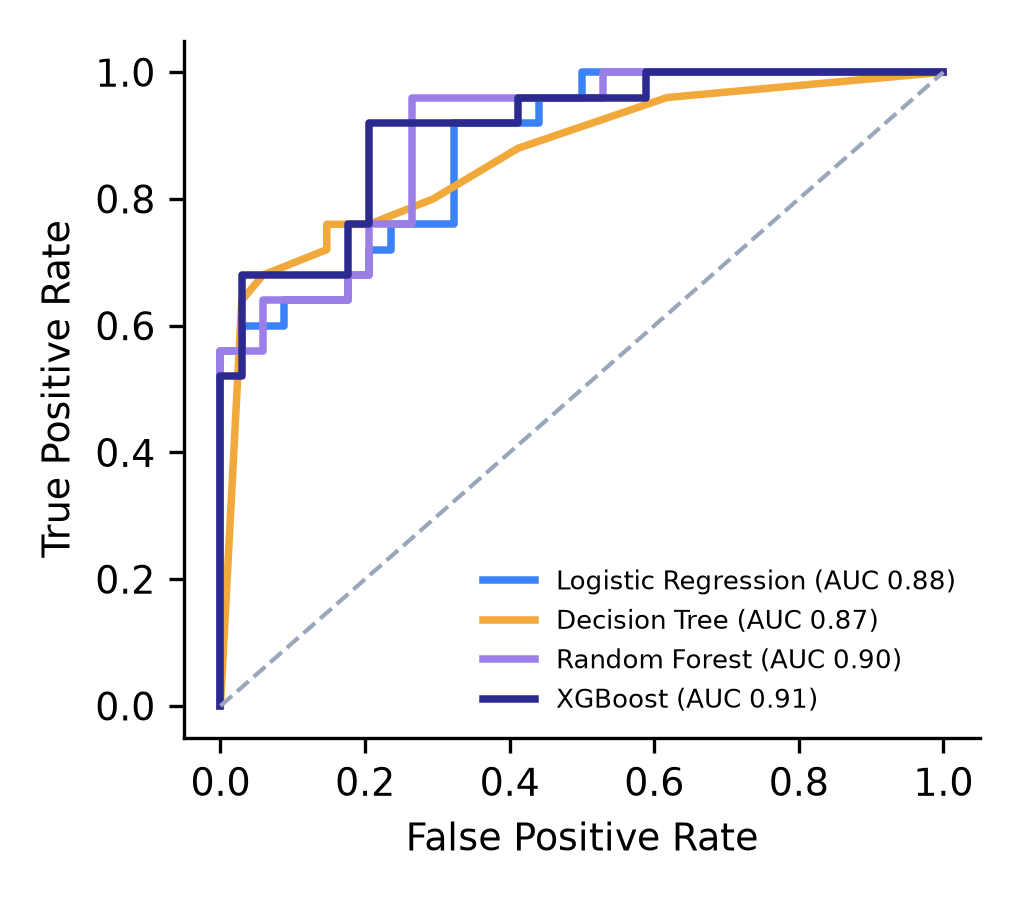

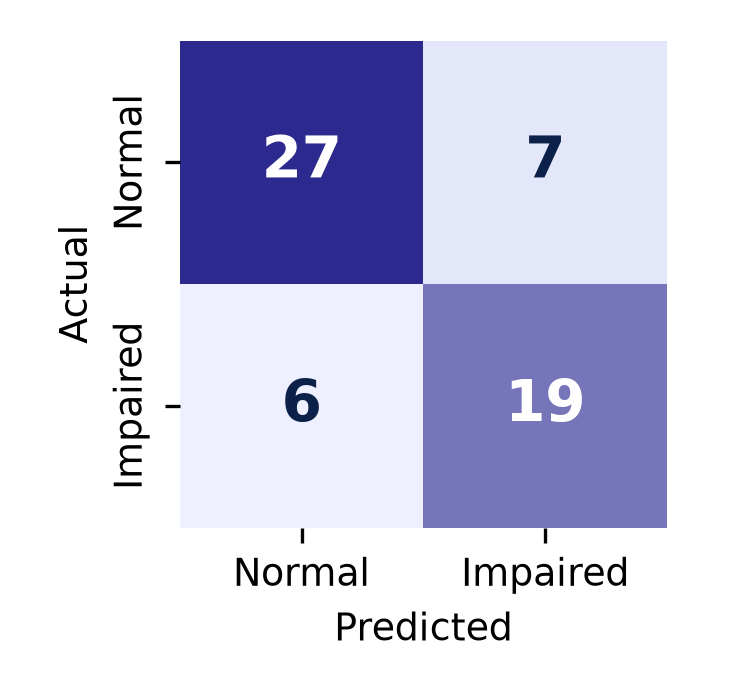

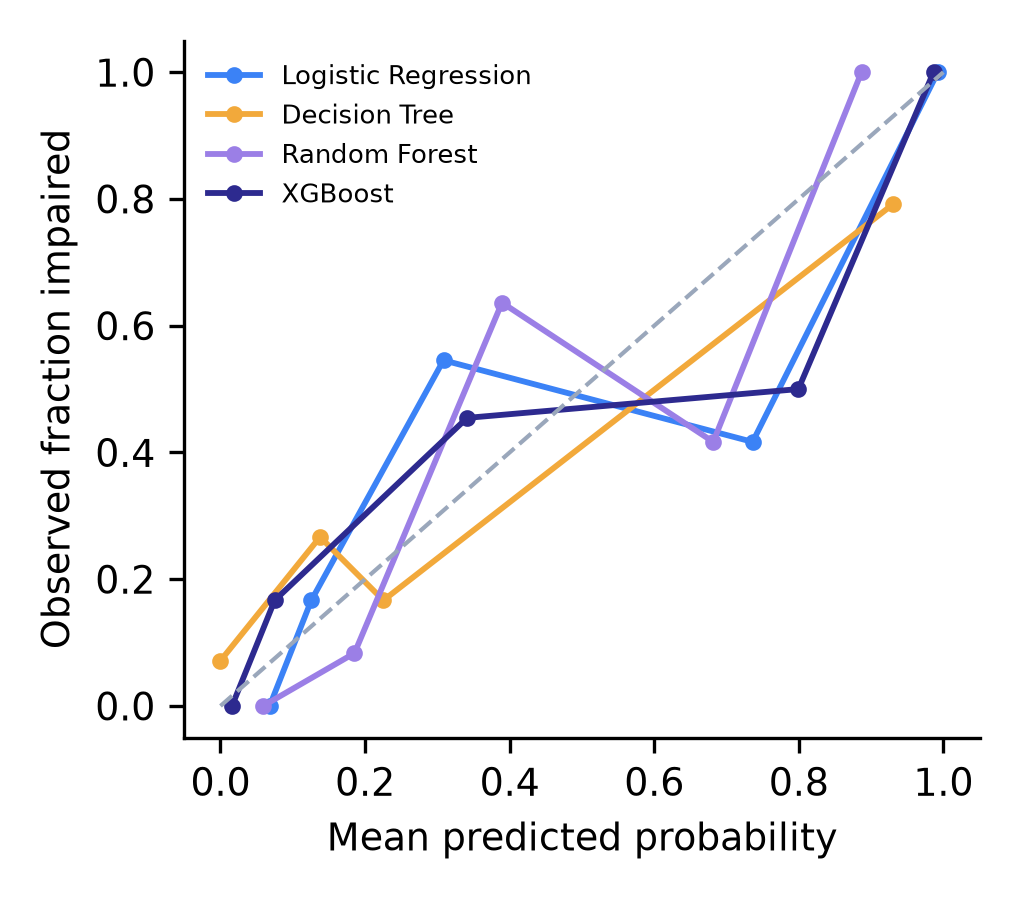

In [11]:
core = ['Logistic Regression','Decision Tree','Random Forest','XGBoost']
evaluate.plot_roc(y_te, {k: probs[k] for k in core}, {k: {'roc_auc': rows[k]['roc_auc']} for k in core}, FIG_DIR/'roc_curves.png')
display(Image(FIG_DIR/'roc_curves.png', width=430))
cm = evaluate.test_metrics(y_te, probs['XGBoost'])['confusion_matrix']
evaluate.plot_confusion(cm, FIG_DIR/'confusion_matrix_xgboost.png'); display(Image(FIG_DIR/'confusion_matrix_xgboost.png', width=300))
evaluate.plot_calibration(y_te, {k: probs[k] for k in core}, FIG_DIR/'calibration.png'); display(Image(FIG_DIR/'calibration.png', width=430))

XGBoost is selected: highest 5-fold CV ROC-AUC (most stable) and highest test ROC-AUC. The Decision Tree is best on accuracy/F1 at the 0.5 threshold, but that advantage is threshold-specific on a 59-subject test set.

## 7. Explainability with SHAP

{'MMSE': 2.0998, 'nWBV': 0.811, 'Age': 0.521, 'eTIV': 0.3483, 'SES': 0.2888, 'Gender': 0.218, 'Educ': 0.077, 'ASF': 0.0468}


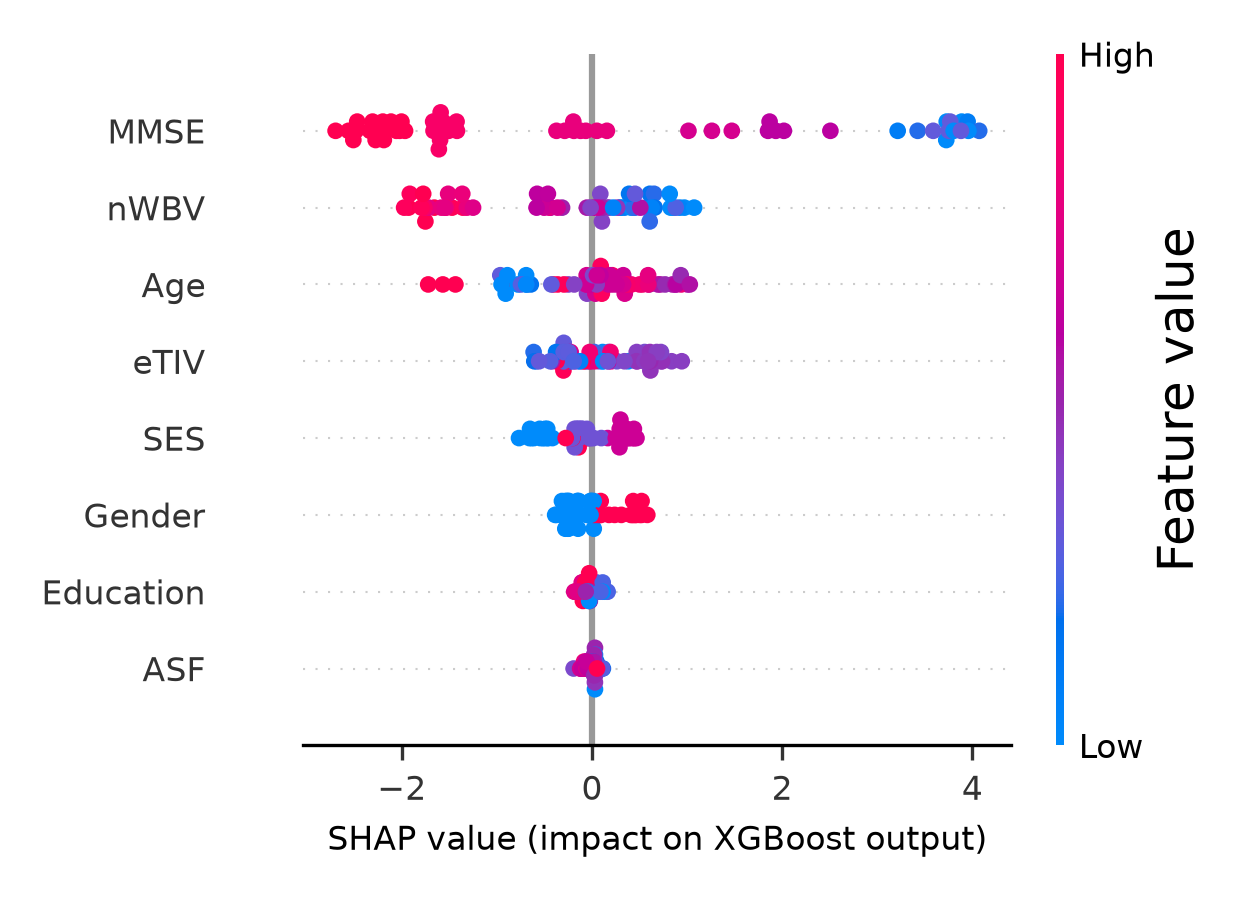

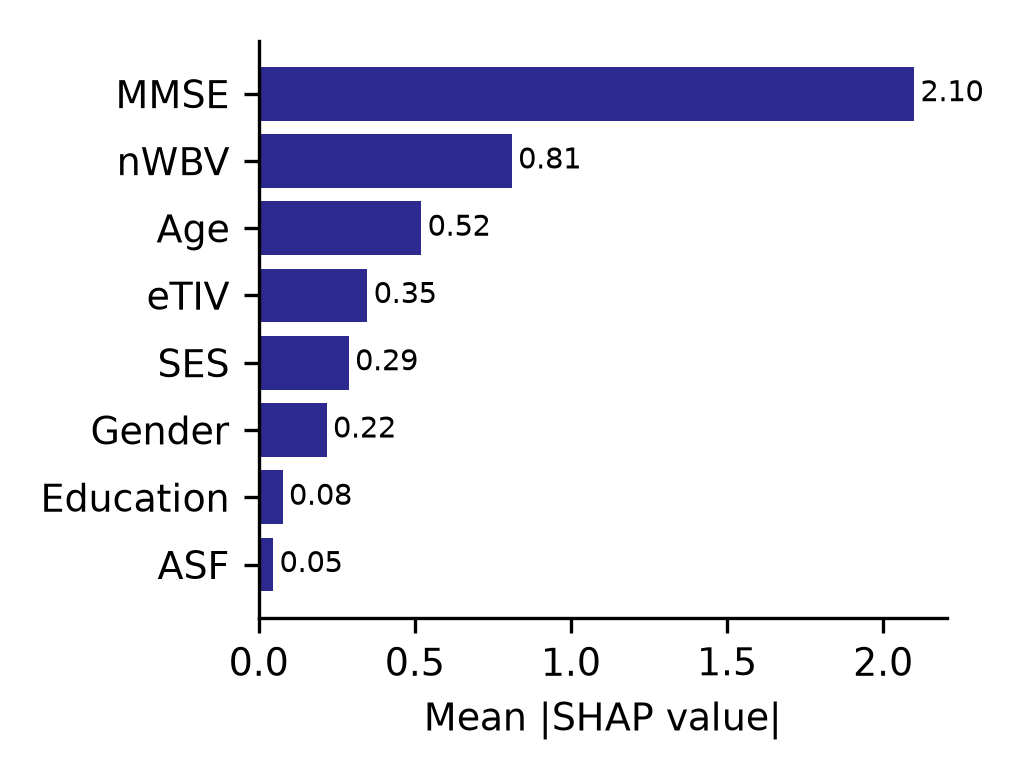

In [12]:
explainer, sv, Xi = explain.shap_values(zoo['XGBoost'], X_te)
imp = explain.global_importance(sv, X_te.columns); print(imp)
explain.plot_summary(sv, Xi, FIG_DIR/'shap_summary.png'); display(Image(FIG_DIR/'shap_summary.png', width=480))
explain.plot_bar(imp, FIG_DIR/'shap_importance_bar.png'); display(Image(FIG_DIR/'shap_importance_bar.png', width=420))

{'Age': 80.0, 'Gender': 0.0, 'Educ': 3.0, 'SES': 2.0, 'MMSE': 20.0, 'eTIV': 1732.0, 'nWBV': 0.692, 'ASF': 1.013} p = 0.995


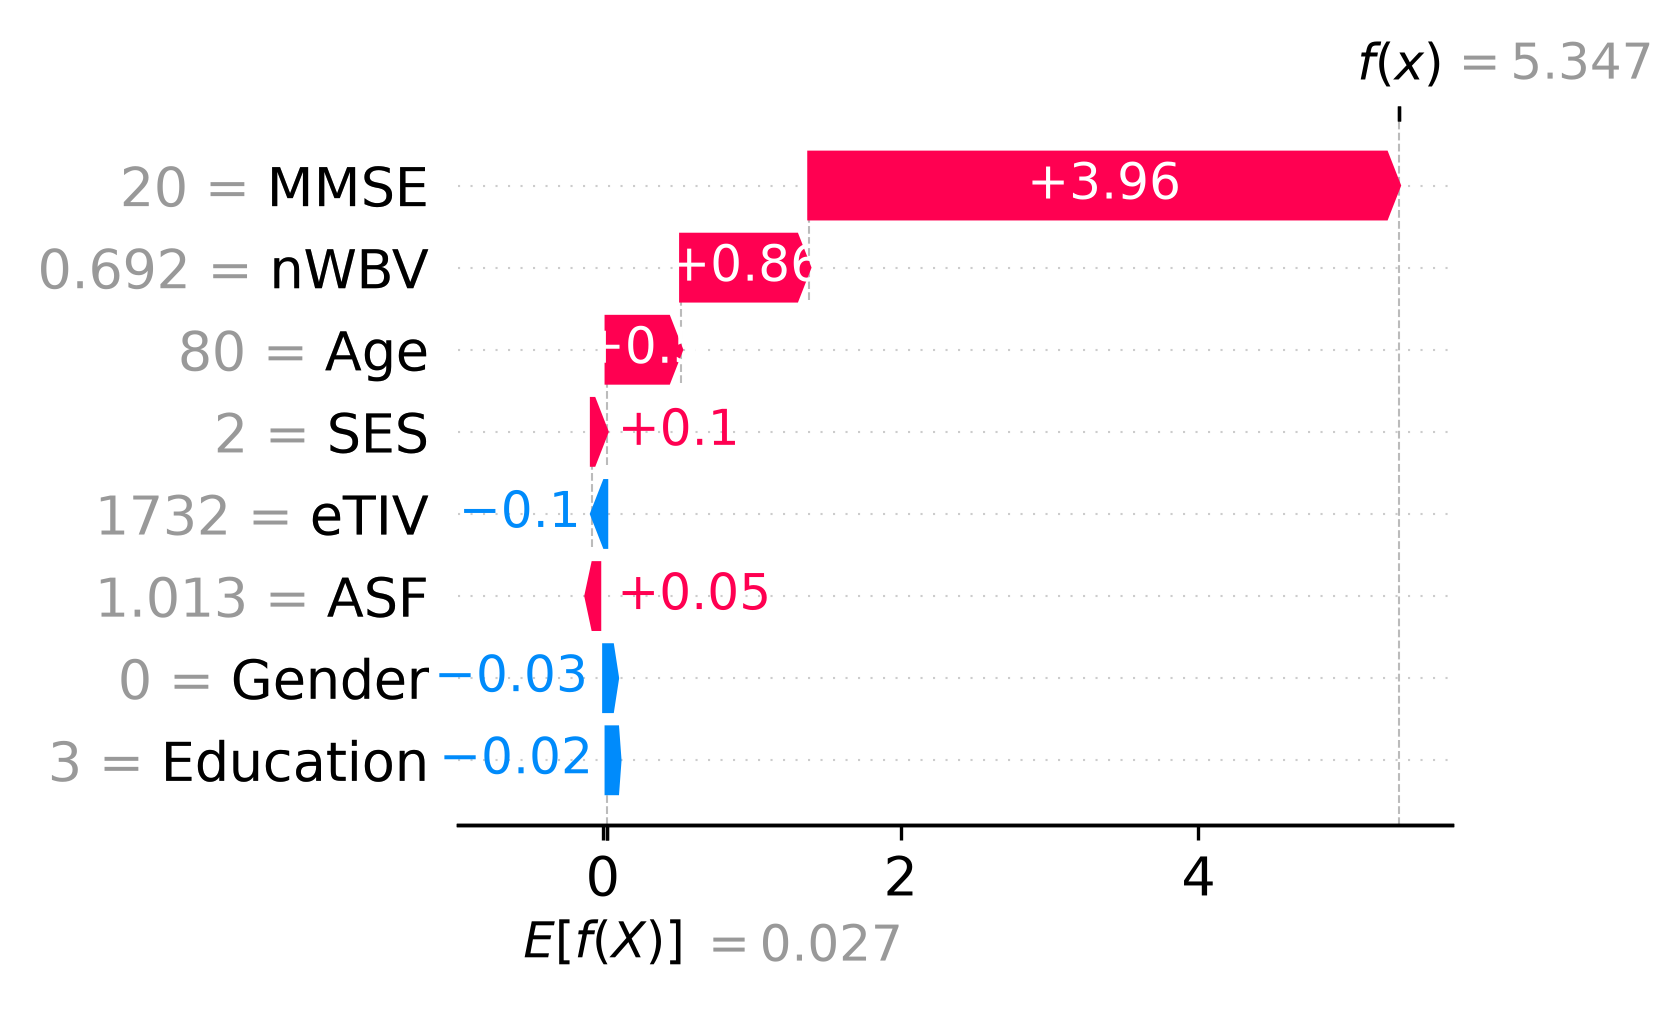

In [13]:
# Local explanation for the impaired test patient with the highest predicted probability
cand = np.where(y_te.values == 1)[0]; row = int(cand[np.argmax(probs['XGBoost'][cand])])
print(X_te.iloc[row].to_dict(), 'p =', round(float(probs['XGBoost'][row]), 3))
explain.plot_waterfall(explainer, sv, Xi, row, FIG_DIR/'shap_waterfall_patient.png'); display(Image(FIG_DIR/'shap_waterfall_patient.png', width=560))

## 8. Patient-level risk stratification
Provisional cut-offs: Low < 0.30 ≤ Medium ≤ 0.60 < High. These need calibration and external validation before any real use.

In [14]:
risk.tier_table(probs['XGBoost'], y_te)

,n,impaired,impaired_rate
tier,,,
Low,30,3,0.10
Medium,5,4,0.80
High,24,18,0.75


## 9. Ablation — which feature groups carry the signal?

In [15]:
groups = {'All features': FEATURES, 'Without MMSE': DEMOGRAPHIC + MRI, 'MRI only': MRI,
          'Demographic only': DEMOGRAPHIC, 'MMSE only': COGNITIVE, 'MMSE + MRI': COGNITIVE + MRI}
abl = {}
for g, f in groups.items():
    for name in ['Logistic Regression', 'XGBoost']:
        mu, sd = evaluate.cv_auc(models.build_models(y_tr)[name], df[f], df['target'])
        abl.setdefault(g, {})[name] = f'{mu:.3f} ± {sd:.3f}'
pd.DataFrame(abl).T

,Logistic Regression,XGBoost
All features,0.901 ± 0.036,0.914 ± 0.027
Without MMSE,0.789 ± 0.055,0.706 ± 0.088
MRI only,0.787 ± 0.032,0.699 ± 0.103
Demographic only,0.711 ± 0.098,0.696 ± 0.067
MMSE only,0.887 ± 0.039,0.883 ± 0.035
MMSE + MRI,0.909 ± 0.036,0.905 ± 0.030


## 10. Conclusions
* Combining cognitive, MRI and demographic features gives CV ROC-AUC 0.86–0.92 across models; XGBoost is best (0.919 ± 0.028).
* MMSE carries most of the signal (MMSE alone ≈ 0.88 AUC). Without MMSE, MRI + demographics still reach ≈ 0.79 with Logistic Regression.
* SHAP agrees with clinical knowledge: low MMSE and low nWBV (atrophy) raise predicted risk.
* Risk tiers separate patients well (10 % impaired in Low vs 76 % in High), but thresholds are provisional.

*Research prototype — not a clinically validated diagnostic tool.*